# Evaluation dataset preparation

This notebook prepares the Steam reviews dataset (`data/external/recommendations.csv`, ~41M rows) for evaluating the recommender. The recommender represents each game as a feature vector and recommends games by cosine similarity to the profile of the games a user liked. To evaluate it, we need users with a history of liked games that the system can actually score.

## 1. Load the data and keep only positive reviews

The file is ~1.9 GB, so columns are loaded with compact dtypes (`int32`, `float32`, `bool`) to reduce memory usage. The dataset has no missing values, so no imputation is needed.

Only reviews with `is_recommended == True` are kept. A positive review is our signal that a user liked a game. Negative reviews would describe what the user *doesn't* want, which the similarity-based recommender does not use.

In [1]:
from pathlib import Path

import pandas as pd

DATA_PATH = Path("../../../data/external/recommendations.csv")

df = pd.read_csv(
    DATA_PATH,
    dtype={
        "app_id": "int32",
        "helpful": "int32",
        "funny": "int32",
        "is_recommended": "bool",
        "hours": "float32",
        "user_id": "int32",
        "review_id": "int32",
    },
    parse_dates=["date"],
)

# number of rows left after each step, plotted in the summary
step_sizes = {"All reviews": len(df)}

df = df[df["is_recommended"]]
step_sizes["Positive reviews only"] = len(df)
print(df.shape)

(35304398, 8)


## 2. Remove duplicate user–game pairs

A user appearing in many rows is expected, since each row is a review of a different game. However, the same user reviewing the **same game** more than once is a true duplicate and would count that game twice in the user's history. Only the first occurrence of each `(user_id, app_id)` pair is kept. This affects only a handful of rows.

In [2]:
df = df.drop_duplicates(["user_id", "app_id"])
step_sizes["Duplicates removed"] = len(df)
print(df.shape)

(35304383, 8)


## 3. Keep only games that have a feature vector

The recommender can only score games in `data/parquet/games_fully_vectorized.parquet`, the same file the backend loads in `src/backend/cosine_similarity.py`. Reviews of games outside that file are dropped. The backend skips unknown `appid`s without an error, so leaving them in would quietly make users' histories shorter than they look.

This step runs **before** the minimum-games filter, so every user who survives step 4 has enough games the system can use.

In [3]:
VECTORS_PATH = Path("../../../data/parquet/games_fully_vectorized.parquet")

vectorized_ids = pd.read_parquet(VECTORS_PATH, columns=["appid"])["appid"]
df = df[df["app_id"].isin(vectorized_ids)]
step_sizes["Games with a vector only"] = len(df)
print(df.shape)

(32995756, 8)


## 4. Keep only users with at least `MIN_GAMES_PER_USER` liked games

Evaluation hides some of a user's liked games and checks whether the recommender suggests them from the rest. That requires enough history to split. Users with very few games (more than half of all users have only one review) cannot be evaluated this way, so only users with 4 or more liked games are kept.

In [4]:
MIN_GAMES_PER_USER = 4

games_per_user = df.groupby("user_id")["app_id"].transform("size")
df = df[games_per_user >= MIN_GAMES_PER_USER].reset_index(drop=True)
step_sizes[f"Users with {MIN_GAMES_PER_USER}+ games only"] = len(df)
print(df.shape)

(18745478, 8)


## 5. Summary of the final dataset

This cell prints the size of the prepared dataset, the number of unique users and games, the date range, and memory usage. It also prints:

- **density**: the share of the user × game matrix that is filled
- **games per user**: how much history each user has
- **users per game**: how popular each game is

Many games have only a few users, so popular games dominate the dataset.

The chart below shows how many rows are left after each step, as a share of the original dataset.

In [5]:
games_per_user = df.groupby("user_id").size()
users_per_game = df.groupby("app_id").size()

print(f"rows:          {len(df):,}")
print(f"unique users:  {df['user_id'].nunique():,}")
print(f"unique games:  {df['app_id'].nunique():,}")
print(f"date range:    {df['date'].min().date()} .. {df['date'].max().date()}")
print(f"memory:        {df.memory_usage(deep=True).sum() / 1024**2:,.0f} MB")
print(f"density:       {len(df) / (games_per_user.size * users_per_game.size):.6%}")
print("\ngames per user:")
print(games_per_user.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print("\nusers per game:")
print(users_per_game.describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).round(2).to_string())
print()
df.info()

rows:          18,745,478


unique users:  2,075,743
unique games:  33,914
date range:    2010-10-15 .. 2022-12-31
memory:        590 MB
density:       0.026628%

games per user:
count    2075743.00
mean           9.03
std           13.95
min            4.00
25%            4.00
50%            6.00
75%            9.00
90%           16.00
99%           51.00
max         3497.00

users per game:
count     33914.00
mean        552.74
std        3292.77
min           1.00
25%           8.00
50%          24.00
75%         112.00
90%         594.00
99%       12204.40
max      133963.00

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18745478 entries, 0 to 18745477
Data columns (total 8 columns):
 #   Column          Dtype         
---  ------          -----         
 0   app_id          int32         
 1   helpful         int32         
 2   funny           int32         
 3   date            datetime64[ns]
 4   is_recommended  bool          
 5   hours           float32       
 6   user_id         int32         
 7 

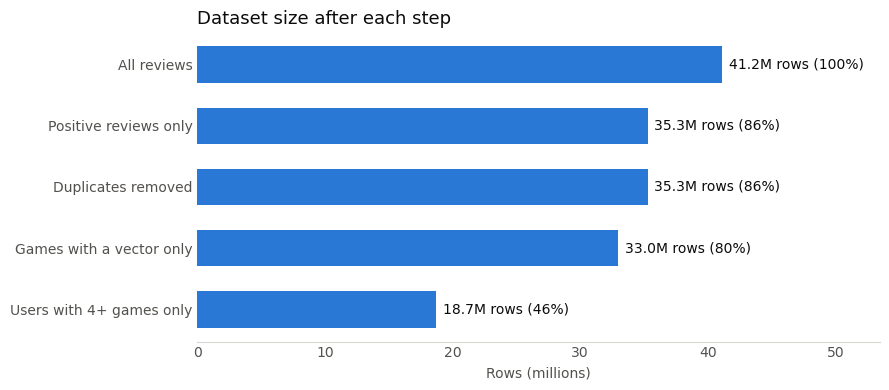

In [6]:
import matplotlib.pyplot as plt

labels = list(step_sizes)
sizes = list(step_sizes.values())
total = sizes[0]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(labels, [s / 1e6 for s in sizes], color="#2a78d6", height=0.6)
ax.invert_yaxis()  # first step at the top

for bar, size in zip(bars, sizes):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{size / 1e6:.1f}M rows ({size / total:.0%})",
            va="center", color="#0b0b0b")

ax.set_title("Dataset size after each step", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Rows (millions)", color="#52514e")
ax.set_xlim(0, total / 1e6 * 1.3)
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()

## 6. Save the prepared dataset

The final dataset is saved to `data/external/recommendations_ready.json` as a map from each user to the games they recommended:

```json
{"<user_id>": [app_id, app_id, ...], ...}
```

JSON keys are always strings, so `user_id` is stored as a string and the `app_id`s stay integers. Each user's games are listed in the order they were reviewed, oldest first.

In [7]:
import json

OUTPUT_PATH = Path("../../../data/external/recommendations_ready.json")

user_games = (
    df.sort_values(["user_id", "date"], kind="stable")
    .groupby("user_id")["app_id"]
    .agg(list)
)
recommendations = {str(user_id): [int(a) for a in app_ids] for user_id, app_ids in user_games.items()}

with open(OUTPUT_PATH, "w") as f:
    json.dump(recommendations, f, separators=(",", ":"))

print(f"saved {len(recommendations):,} users to {OUTPUT_PATH} ({OUTPUT_PATH.stat().st_size / 1024**2:,.0f} MB)")

saved 2,075,743 users to ../../../data/external/recommendations_ready.json (149 MB)


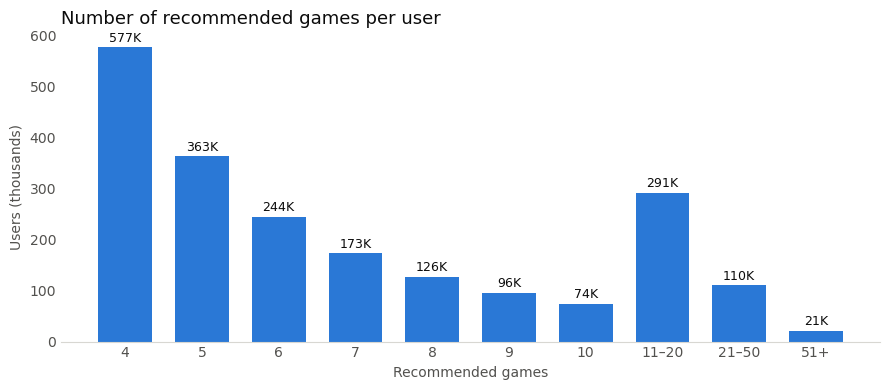

In [8]:
games_per_user = pd.Series([len(app_ids) for app_ids in recommendations.values()])

# a few users have thousands of games, so the long tail is grouped into ranges
bins = [3, 4, 5, 6, 7, 8, 9, 10, 20, 50, games_per_user.max()]
bin_labels = ["4", "5", "6", "7", "8", "9", "10", "11–20", "21–50", "51+"]
users_per_bin = pd.cut(games_per_user, bins=bins, labels=bin_labels).value_counts(sort=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(users_per_bin.index.astype(str), users_per_bin.values / 1e3, color="#2a78d6", width=0.7)

for bar, count in zip(bars, users_per_bin.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 5,
            f"{count / 1e3:.0f}K", ha="center", va="bottom", color="#0b0b0b", fontsize=9)

ax.set_title("Number of recommended games per user", loc="left", fontsize=13, color="#0b0b0b")
ax.set_xlabel("Recommended games", color="#52514e")
ax.set_ylabel("Users (thousands)", color="#52514e")
ax.tick_params(colors="#52514e", length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color("#d8d7d2")
plt.tight_layout()
plt.show()